# High-variance Gaussian linear control

This control is kept separately from the ten conditions in the main 20-variable comparison. Scores are averaged across model seeds within each dataset instance. The reference has the same noise family and linear mechanism with the lower Gaussian noise variance.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark/control")


,setting,model,mean,std,size
0,Gaussian,AVICI,0.446184,0.113053,15
1,Gaussian,DAGMA_Linear,0.189695,0.088932,15
2,Gaussian,DAGMA_Nonlinear,0.127557,0.061664,15
3,Gaussian,DAS,0.107358,0.056255,15
4,Gaussian,DirectLiNGAM,0.333148,0.089045,15
5,Gaussian,FCI,0.088630,0.063446,15
6,Gaussian,GES,0.393808,0.179204,15
7,Gaussian,GOLEM,0.125411,0.047655,15
8,Gaussian,GRaSP,0.794479,0.098063,15
9,Gaussian,GraNDAG,0.050703,0.033839,15


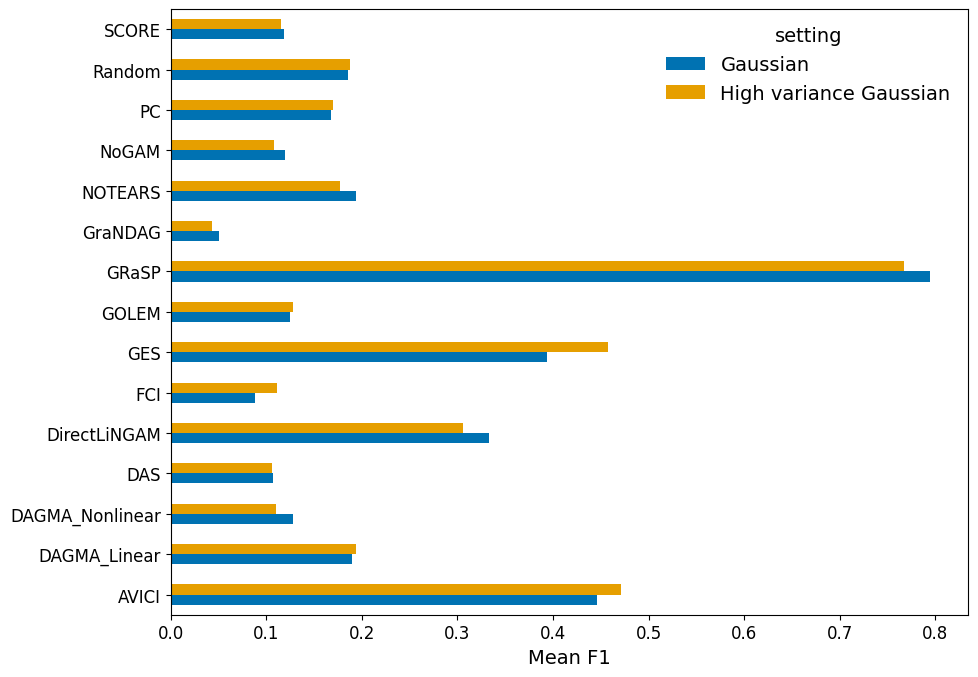

In [2]:
from condition_data import load_results

control = load_results("benchmark_control")
reference = load_results("benchmark", n_variables=20)
reference = reference.loc[reference.dataset.eq("20nodes_EB_obsconf0_latconf0_Gaussian_Linear")]
control["setting"] = "High variance Gaussian"
reference["setting"] = "Gaussian"
runs = pd.concat([reference, control], ignore_index=True)
blocks = runs.loc[runs.status.eq("finished")].groupby(["setting", "model", "dataset_seed"]).f1.mean().reset_index()
summary = blocks.groupby(["setting", "model"]).f1.agg(["mean", "std", "size"]).reset_index()
display(summary)
wide = summary.pivot(index="model", columns="setting", values="mean")
ax = wide.plot.barh(figsize=(10, 7), xlabel="Mean F1", ylabel="")
ax.figure.tight_layout()
th.save_pdf(ax.figure, "gaussian_linear_control.pdf")
display(ax.figure)
plt.close(ax.figure)
